## Exercise 1.2
## Classification of MNIST digits with a convolutional neural network

In this exercise we will classify MNIST digits again, but this time we will use a convolutional neural network (CNN).

First we import the modules we need

In [2]:
import numpy as np
from tqdm.notebook import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets as datasets
from torch.utils.data import DataLoader
import torchvision.transforms as transforms

We check that this script has a GPU available

Notice: there is no NVIDIA CHIP in the Macbook, but we can use mps if the model over M1

In [6]:
if torch.cuda.is_available():
    device = torch.device('cuda')
    print("The code will run on GPU (CUDA).")
elif torch.backends.mps.is_available():
    device = torch.device('mps')
    print("The code will run on Apple GPU (MPS).")
else:
    device = torch.device('cpu')
    print("The code will run on CPU.")

The code will run on Apple GPU (MPS).


We import the MNIST dataset, which is built into pytorch

In [3]:
batch_size = 64
trainset = datasets.MNIST('./data', train=True, download=True, transform=transforms.ToTensor())
train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=1)
testset = datasets.MNIST('./data', train=False, download=True, transform=transforms.ToTensor())
test_loader = DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=1)

You should implement a network to classify MNIST digits. 
The network should consist of two parts, a part with convolutions and one with fully connected layers.
The convolutional part we will call `convolutional`, and it should contain the follwing:
* two convolutional layers with 8 features
```
    ps: 8 features其实就是一层有8个不同的核同时工作，然后产出8张图叠成通道。不是8个探测器排成一条流水线。流水线是conv层1->conv层2。至于为什么需要多个核是因为每个kernel的作用不一样，有的是负责检测竖线，有的是负责检测圈圈etc
```
* a $2\times2$ max pooling layer
```
    这个Max Pooling就是取window内最大的值。除了max pooling还有其他的pooling。pooling的作用是压缩需要训练的数据。其次还有reduce overfitting的作用。
```
* two convolutional layers with 16 features

The convolutions should be $3\times 3$, and should not change the size of the output. What does this mean that the stride and padding should be?

For example check the documentation of the `nn` module https://pytorch.org/docs/stable/nn.html

**Remember**: There's a specific type of layer that you should always have after a convolution or a fully connected layer. What is this type of layer called?

In [ ]:
class Network(nn.Module):
    def __init__(self):
        super(Network, self).__init__()
        self.convolutional = nn.Sequential(
                nn.Conv2d(1, 8, kernel_size = 3, stride=1, padding=1),
                nn.ReLU(),
                nn.Conv2d(8, 8, kernel_size = 3, stride=1, padding=1),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2, stride=2),
                nn.Conv2d(8, 16, kernel_size = 3, stride=1, padding=1),
                nn.ReLU(),
                nn.Conv2d(16, 16, kernel_size = 3, stride=1, padding=1),
                nn.ReLU(),
                )

        self.fully_connected = nn.Sequential(
                nn.Linear(14*14*16, 500),
                nn.ReLU(),
                nn.Linear(500, 10),
                nn.Softmax(dim=1))
    
    def forward(self, x):
        x = self.convolutional(x)
        #reshape x so it becomes flat, except for the first dimension (which is the minibatch)
        x = x.view(x.size(0), -1)
        x = self.fully_connected(x)
        return x

We instantiate a copy of our network, transfer it to the GPU if it's available.
We also check if the dimensions of our network match.

In [5]:
model = Network()
model.to(device)
#Initialize the optimizer
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

#Get the first minibatch
data = next(iter(train_loader))[0].to(device)
#Try running the model on a minibatch
print('Shape of the output from the convolutional part', model.convolutional(data).shape)
model(data); #if this runs the model dimensions fit  如果跑不通会报错，跑通了就没反应

NameError: name 'device' is not defined

注意这一步其实没有训练，训练是指loss->backward->step->optimizer.step()
然后修改权重，但这里只是forward，没有backward，所以没有训练。目的是检查shape正确与否

We train this network for five epochs

In [6]:
num_epochs = 5

for epoch in tqdm(range(num_epochs), unit='epoch'):
    #For each epoch
    train_correct = 0
    for minibatch_no, (data, target) in tqdm(enumerate(train_loader), total=len(train_loader)):
        data, target = data.to(device), target.to(device)
        #Zero the gradients computed for each weight
        optimizer.zero_grad()
        #Forward pass your image through the network
        output = model(data)
        #Compute the loss
        loss = F.nll_loss(torch.log(output), target)
        #Backward pass through the network
        loss.backward()
        #Update the weights
        optimizer.step()
        
        #Compute how many were correctly classified
        predicted = output.argmax(1)
        train_correct += (target==predicted).sum().cpu().item()
    #Comput the test accuracy
    test_correct = 0
    for data, target in test_loader:
        data = data.to(device)
        with torch.no_grad():
            output = model(data)
        predicted = output.argmax(1).cpu()
        test_correct += (target==predicted).sum().item()
    train_acc = train_correct/len(trainset)
    test_acc = test_correct/len(testset)
    print("Accuracy train: {train:.1f}%\t test: {test:.1f}%".format(test=100*test_acc, train=100*train_acc))

  0%|          | 0/5 [00:00<?, ?epoch/s]

  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 88.1%	 test: 97.7%


  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 98.2%	 test: 98.3%


  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 98.8%	 test: 98.8%


  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 99.2%	 test: 98.7%


  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 99.5%	 test: 98.8%


Hopefully you now have a model that's able to achieve decent performance on MNIST.
It should have around 97.5% accuracy on the test set after the first epoch.

* Why is the accuracy on the training set higher than on the test set? (recall from machine learning)

```
   The training data is involved in fitting, but test data is not. So the performance on train is better
```

* Why does it have higher accuracy on the test set than the training set after the first epoch?

```
   So at the end of the 1st round: the test uses the network that has just completed a full training pass, while the train set contains mnay batches that are still under tranined. As a result, test performance becomes better than train performance. In the subsequent rounds, the model become stable, this gap narrows, and typically train performance is greater than or equal to test performance cuz the training data is invloved in fitting and training model process. That's one of the reason of causing overfitting.
```

### Data augmentation

Question: How does this affect your training and testing loss?
```
The role of data augmentation: use cheap and random augmentation to expand effective training samples, forcing model to learn the invarient features instead of memorizing fixles

```
 * Add random rotations to the MNIST digits during training (you have to go back and modify the dataloader)
 
  hint: you can use `transforms.RandomRotation` 
  
  hint: you can combine multiple transforms into one with `transforms.Compose`


 * Try plotting some of the augmented images, to visually confirm what your augmentation is doing.

 * Try adding another type of data augmentation.

In [7]:
batch_size = 64

# randomly rotate the image +-15 degrees, then convert to tensor
train_transform = transforms.Compose([
    transforms.RandomRotation(15),
    transforms.ToTensor()
])

# test:
test_transform = transforms.Compose([
    transforms.ToTensor()
])

trainset = datasets.MNIST('./data', train=True, download=True, transform=train_transform)
testset = datasets.MNIST('./data', train=False, download=True, transform=test_transform)

train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=1)
test_loader = DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=1)


数据格改完并 **已经跑过** 之后，按这个顺序再跑三格：

**1. 重新创建模型和优化器**（必须，否则还是旧权重接着练）

就是原来的：

```python
model = Network()
model.to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
```
Otimizer的作用和用法：根据loss.backward()写在每个权重上的梯度，去改model里的参数。网络自己不会更新.step() 才是「拧旋钮」。

using method
```
optimizer.zero_grad()   # 擦掉上批梯度
output = model(data)
loss = ...
loss.backward()         # 算出新梯度
optimizer.step()        # 按梯度改权重
```
换模型必须 重新建 optimizer（model = Network() 之后再写那行），否则还绑着旧网络。检查 shape、画图、测试 都不用 optimizer。

`model = Network()` 会新建随机权重。不跑这一格，等于在「没增强时已经 98% 的模型」上继续训，看不出增强本身的效果。

**2. 可选：检查 shape 那一格**（`model.convolutional(data)` 那格）

**3. 再跑原来的 `num_epochs = 5` 训练循环**

那个 `for epoch ...` 会自动用 **新的** `train_loader`（带旋转）和原来的 `test_loader`（不旋转）。

---

不要做：

- 不要再写 `model = NetworkBetter()` 之类除非你想换结构  
- 不要只跑训练循环、漏掉 `model = Network()`

跑完看打印的 `Accuracy train / test`，和没增强时那次对比即可。

Try plotting some of the augmented images, to visually confirm what your augmentation is doing.

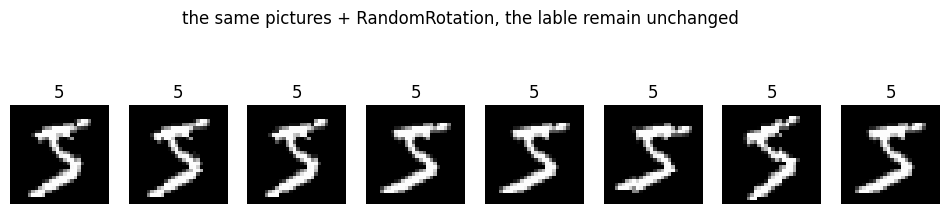

In [11]:
# 训练集第 0 张，取 8 次，每次 RandomRotation 不同
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 3))
for i in range(8):
    img, label = trainset[0]          # 每次 __getitem__ 都会重新做 transform
    plt.subplot(1, 8, i + 1)
    plt.imshow(img.numpy()[0], "gray")
    plt.title(str(label))
    plt.axis("off")
plt.suptitle("the same pictures + RandomRotation, the lable remain unchanged")
plt.show()

In [ ]:
model = Network()
model.to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

In [14]:
num_epochs = 5

for epoch in tqdm(range(num_epochs), unit='epoch'):
    #For each epoch
    train_correct = 0
    for minibatch_no, (data, target) in tqdm(enumerate(train_loader), total=len(train_loader)):
        data, target = data.to(device), target.to(device)
        #Zero the gradients computed for each weight
        optimizer.zero_grad()
        #Forward pass your image through the network
        output = model(data)
        #Compute the loss
        loss = F.nll_loss(torch.log(output), target)
        #Backward pass through the network
        loss.backward()
        #Update the weights
        optimizer.step()
        
        #Compute how many were correctly classified
        predicted = output.argmax(1)
        train_correct += (target==predicted).sum().cpu().item()
    #Comput the test accuracy
    test_correct = 0
    for data, target in test_loader:
        data = data.to(device)
        with torch.no_grad():
            output = model(data)
        predicted = output.argmax(1).cpu()
        test_correct += (target==predicted).sum().item()
    train_acc = train_correct/len(trainset)
    test_acc = test_correct/len(testset)
    print("Accuracy train: {train:.1f}%\t test: {test:.1f}%".format(test=100*test_acc, train=100*train_acc))

  0%|          | 0/5 [00:00<?, ?epoch/s]

  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 87.8%	 test: 97.7%


  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 97.5%	 test: 98.5%


  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 98.1%	 test: 98.7%


  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 98.4%	 test: 98.8%


  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 98.9%	 test: 98.5%


### Explore the model
What has the model learned? You can access all the weights in the model with `model.parameters()`. Here we just print the shape.
 - Try showing images of the filters in the first layer. 
 - Can you from the dimensions of the weights alone identify which layer it is in our model?

In [15]:
[w.shape for w in model.parameters()]

[torch.Size([8, 1, 3, 3]),
 torch.Size([8]),
 torch.Size([8, 8, 3, 3]),
 torch.Size([8]),
 torch.Size([16, 8, 3, 3]),
 torch.Size([16]),
 torch.Size([16, 16, 3, 3]),
 torch.Size([16]),
 torch.Size([500, 3136]),
 torch.Size([500]),
 torch.Size([10, 500]),
 torch.Size([10])]

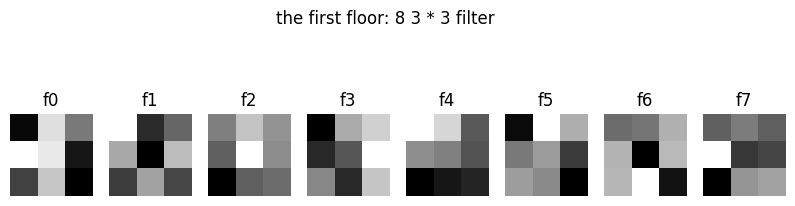

In [18]:
# 取出第一层卷积的 weight: (8, 1, 3, 3)
first_conv = None
for m in model.modules():
    if isinstance(m, nn.Conv2d):
        first_conv = m
        break

W = first_conv.weight.detach().cpu()   # 不要带着梯度画图

plt.figure(figsize=(10, 3))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(W[i, 0], cmap="gray")   # [哪个filter, 哪个输入通道, H, W]
    plt.title(f"f{i}")
    plt.axis("off")
plt.suptitle("the first floor: 8 3 * 3 filter")
plt.show()

### Dropout
 * Try adding dropout to your model.
 
You can add it between the convolutional layers and or in the fully connected part.

Remember to call `net.train()` and `net.eval()` to change the model from test to training state, so it knows when you want it to apply dropout.


先纠正一句：Dropout **不一定让训练准确率更高**，它是让 **测试/泛化更好**。训练集上往往更难、train acc 可能略降，这才正常。

---

### 原理（为什么有时 test 更好）

隐藏层神经元很容易 **互相勾结**：A 必须配合 B 才能认「7」。测试时稍微变一点，这套默契就崩。

Dropout 在 **每一次前向** 随机把一部分激活变成 0：

- 不能只靠某几个神经元，特征要分散、冗余  
- 相当于每次训一个略不同的「瘦网络」，最后测试用完整网络，近似很多小网络投票  

这叫 **正则化**（和数据增强同类：给训练加干扰，换更稳的测试表现）。MNIST 已经 98% 时，Dropout 提升可能很小；热狗那种更容易过拟合的任务更有用。`p` 太大（乱关太多）会欠拟合，test 也会变差。

---

### `train()` 打开、`eval()` 关掉 —— 不单是 Dropout

`model.train()` / `model.eval()` 是整个模块的 **两种工作模式**，会通知 **所有需要区分训练/测试的层**：

| 层 | `train()` | `eval()` |
|---|---|---|
| **Dropout** | 随机关神经元 | 全开，不随机 |
| **BatchNorm**（以后会遇到） | 用当前 batch 的均值方差更新统计 | 用训练期攒下的全局均值方差 |

卷积、ReLU、Linear **不受** 这两个开关影响。  
`torch.no_grad()` **不是一回事**：它只是不算梯度、省内存，**关不掉 Dropout**。测试时通常两个都写：

```python
model.eval()
with torch.no_grad():
    output = model(data)
```

忘了 `eval()`：测试还在随机丢神经元，分数偏低、每次还不一样。

---

### 视频

概念（强烈建议先看，约 7 分钟）：  
[Andrew Ng — Understanding Dropout](https://www.youtube.com/watch?v=ARq74QuavAo)

文字+公式：  
[D2L：Dropout](https://en.d2l.ai/chapter_multilayer-perceptrons/dropout.html)

PyTorch 里 `train`/`eval` 可在 Loeber 的 CNN 那集里对照代码，但原理听吴恩达那条就够。

一句话：**Dropout 用随机「拆帮派」防止过拟合；`train`/`eval` 告诉模型现在是训练还是考试，BatchNorm 也吃这套开关。**

In [ ]:
class Network(nn.Module):
    def __init__(self):
        super(Network, self).__init__()
        self.convolutional = nn.Sequential(
                nn.Conv2d(1, 8, kernel_size = 3, stride=1, padding=1),
                nn.ReLU(),
                nn.Conv2d(8, 8, kernel_size = 3, stride=1, padding=1),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2, stride=2),
                nn.Dropout(p=0.2),
                nn.Conv2d(8, 16, kernel_size = 3, stride=1, padding=1),
                nn.ReLU(),
                nn.Conv2d(16, 16, kernel_size = 3, stride=1, padding=1),
                nn.ReLU(),
                )

        self.fully_connected = nn.Sequential(
                nn.Linear(14*14*16, 500),
                nn.ReLU(),
                nn.Dropout(p=0.5),
                nn.Linear(500, 10),
                nn.Softmax(dim=1))
    
    def forward(self, x):
        x = self.convolutional(x)
        #reshape x so it becomes flat, except for the first dimension (which is the minibatch)
        x = x.view(x.size(0), -1)
        x = self.fully_connected(x)
        return x

In [7]:
model = Network()
model.to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)


num_epochs = 5

for epoch in tqdm(range(num_epochs), unit='epoch'):
    #For each epoch
    model.train()
    train_correct = 0
    for minibatch_no, (data, target) in tqdm(enumerate(train_loader), total=len(train_loader)):
        data, target = data.to(device), target.to(device)
        #Zero the gradients computed for each weight
        optimizer.zero_grad()
        #Forward pass your image through the network
        output = model(data)
        #Compute the loss
        loss = F.nll_loss(torch.log(output), target)
        #Backward pass through the network
        loss.backward()
        #Update the weights
        optimizer.step()
        
        #Compute how many were correctly classified
        predicted = output.argmax(1)
        train_correct += (target==predicted).sum().cpu().item()


    #Comput the test accuracy
    model.eval()
    test_correct = 0
    for data, target in test_loader:
        data = data.to(device)
        with torch.no_grad():
            output = model(data)
        predicted = output.argmax(1).cpu()
        test_correct += (target==predicted).sum().item()
    train_acc = train_correct/len(trainset)
    test_acc = test_correct/len(testset)
    print("Accuracy train: {train:.1f}%\t test: {test:.1f}%".format(test=100*test_acc, train=100*train_acc))


  0%|          | 0/5 [00:00<?, ?epoch/s]

  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 87.8%	 test: 97.7%


  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 98.0%	 test: 98.6%


  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 98.7%	 test: 98.8%


  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 99.1%	 test: 98.7%


  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 99.3%	 test: 98.6%


## Already done?

Try to explore extracting features at different layers of the model and visualizing the corresponding representation of your data using e.g. t-SNE or PCA. Try to understand how those two techniques differ